# Démo plutovizu

Tour d'horizon de l'API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import Chart, get_fonts, list_themes, set_theme, theme_context

## Données d'exemple

In [2]:
rng = np.random.default_rng(42)
n = 120
jours = np.arange(n)
effet_categorie = {'A': 150, 'B': -80, 'C': 40, 'D': -150}

ventes = pd.DataFrame({
    'date': pd.date_range('2024-01-01', periods=n, freq='D'),
    'categorie': rng.choice(list(effet_categorie), n),
    'temperature': rng.normal(27, 4, n).round(1),
})
# tendance + cycle mensuel + effet de la catégorie + bruit
ventes['ventes'] = (np.linspace(900, 1300, n) + 120 * np.sin(jours * 2 * np.pi / 30)
                    + ventes['categorie'].map(effet_categorie) + rng.normal(0, 40, n))
ventes['profit'] = ventes['ventes'] * 0.18 + rng.normal(0, 15, n)
ventes['visiteurs'] = (20 + 2.2 * ventes['temperature'] + rng.normal(0, 6, n)).round().astype(int)
ventes.head()

,date,categorie,temperature,ventes,profit,visiteurs
0,2024-01-01,A,23.5,1045.254467,161.794977,71
1,2024-01-02,D,30.9,789.743793,147.073815,96
2,2024-01-03,C,20.3,1047.771156,214.509061,65
3,2024-01-04,B,25.7,909.393564,140.682920,72
4,2024-01-05,B,27.7,906.185668,176.070840,77


## 1. Courbes

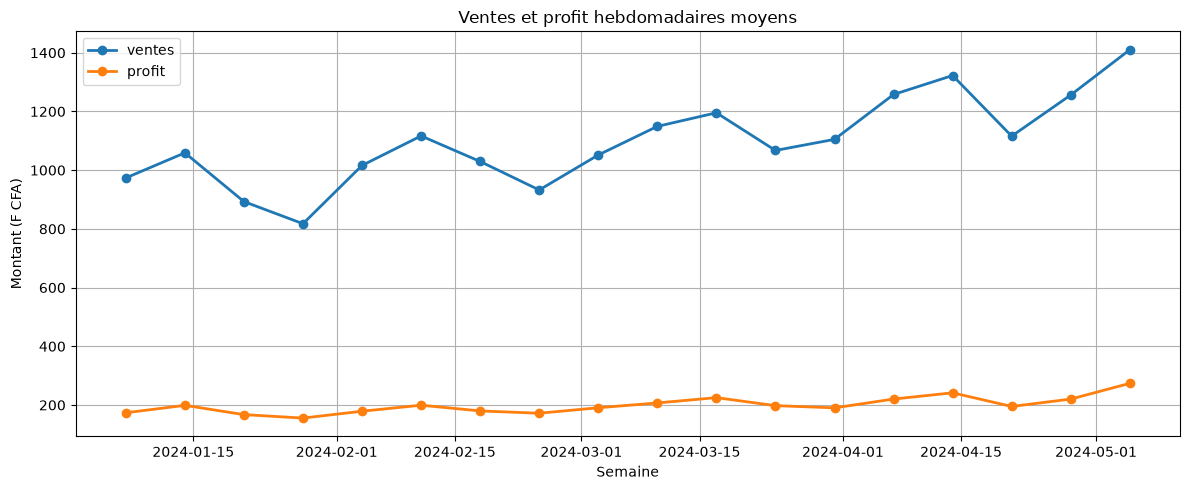

In [3]:
hebdo = ventes.resample('W', on='date')[['ventes', 'profit']].mean().reset_index()

(Chart(hebdo, figsize=(12, 5))
    .line('date', ['ventes', 'profit'])
    .title('Ventes et profit hebdomadaires moyens')
    .labels(xlabel='Semaine', ylabel='Montant (F CFA)')
    .grid()
    .set_legend()
    .tight_layout()
    .show())

## 2. Barres

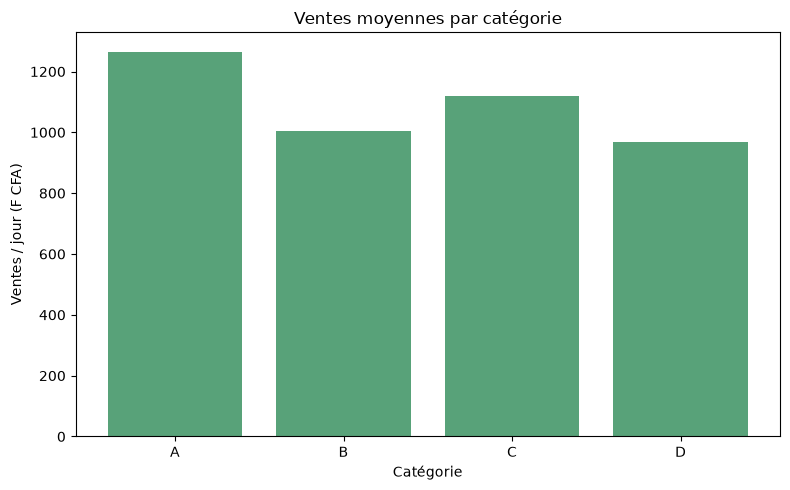

In [4]:
par_categorie = ventes.groupby('categorie', as_index=False)['ventes'].mean()

(Chart(par_categorie, figsize=(8, 5))
    .bar('categorie', 'ventes', color='seagreen')
    .title('Ventes moyennes par catégorie')
    .labels(xlabel='Catégorie', ylabel='Ventes / jour (F CFA)')
    .tight_layout()
    .show())

## 3. Nuage de points

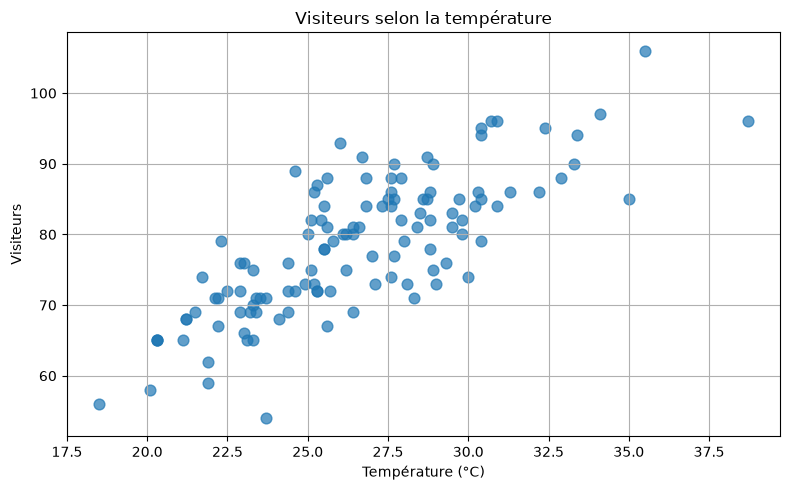

In [5]:
(Chart(ventes, figsize=(8, 5))
    .scatter('temperature', 'visiteurs', size=60)
    .title('Visiteurs selon la température')
    .labels(xlabel='Température (°C)', ylabel='Visiteurs')
    .grid()
    .tight_layout()
    .show())

## 4. Diagramme ombrothermique

Échelle de Gaussen (p = 2T) : un mois est sec quand les précipitations sont inférieures au double de la température.

Analyse des périodes sèches et humides:
Jan: PÉRIODE SÈCHE - Précip: 16.0mm < Seuil: 48.2mm
Fév: PÉRIODE SÈCHE - Précip: 23.9mm < Seuil: 52.2mm
Mar: Période humide - Précip: 86.7mm ≥ Seuil: 53.2mm
Avr: Période humide - Précip: 116.7mm ≥ Seuil: 53.0mm
Mai: Période humide - Précip: 92.9mm ≥ Seuil: 52.2mm
Juin: Période humide - Précip: 147.8mm ≥ Seuil: 50.0mm
Juil: Période humide - Précip: 143.2mm ≥ Seuil: 47.8mm
Août: Période humide - Précip: 215.8mm ≥ Seuil: 47.8mm
Sep: Période humide - Précip: 167.1mm ≥ Seuil: 48.6mm
Oct: Période humide - Précip: 109.4mm ≥ Seuil: 49.6mm
Nov: PÉRIODE SÈCHE - Précip: 30.3mm < Seuil: 49.8mm
Déc: PÉRIODE SÈCHE - Précip: 33.0mm < Seuil: 47.4mm

Résumé: 4 mois secs sur 12 mois


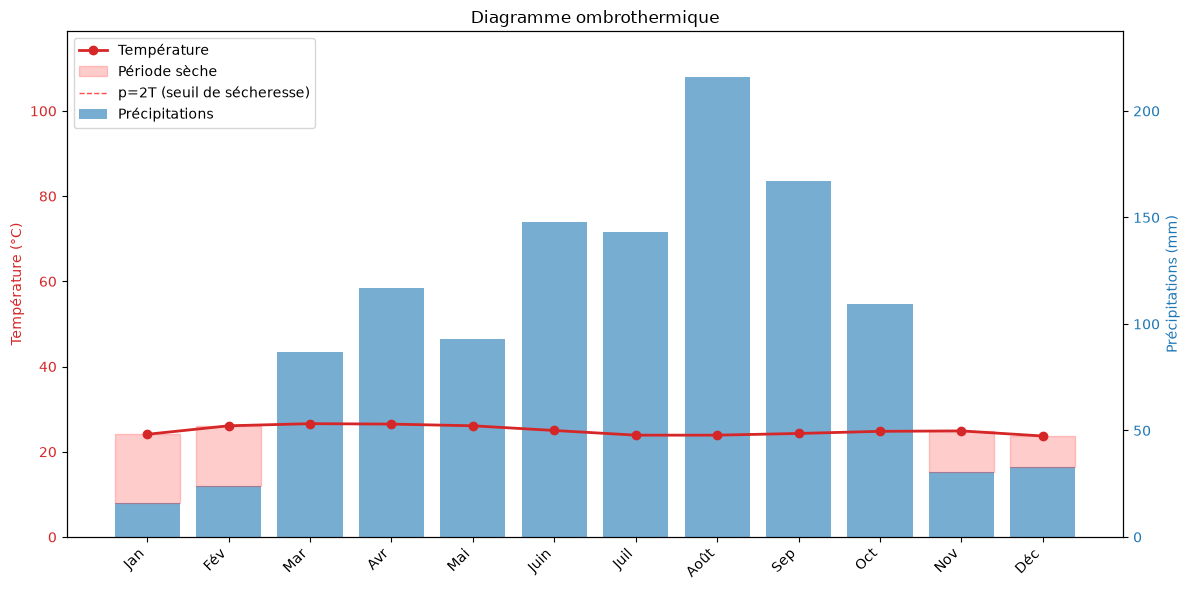

In [6]:
climat = pd.DataFrame({
    'Mois': ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin',
             'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'],
    'Température (°C)': [24.1, 26.1, 26.6, 26.5, 26.1, 25.0,
                         23.9, 23.9, 24.3, 24.8, 24.9, 23.7],
    'Précipitations (mm)': [16, 23.9, 86.7, 116.7, 92.9, 147.8,
                            143.2, 215.8, 167.1, 109.4, 30.3, 33],
})
cols = ('Mois', 'Température (°C)', 'Précipitations (mm)')

(Chart(climat, figsize=(12, 6))
    .ombrothermic(*cols)
    .title('Diagramme ombrothermique')
    .print_ombrothermic_analysis(*cols)
    .tight_layout()
    .show())

## 5. Thèmes

Quatorze thèmes prédéfinis pour sortir du style matplotlib classique. `theme_context` limite le thème à un bloc `with`.

In [7]:
list_themes()

['accessible',
 'arctic',
 'blueprint',
 'editorial',
 'forest',
 'ink',
 'neon',
 'ocean',
 'paper',
 'pastel',
 'pluto',
 'sahel',
 'sunset',
 'terminal']

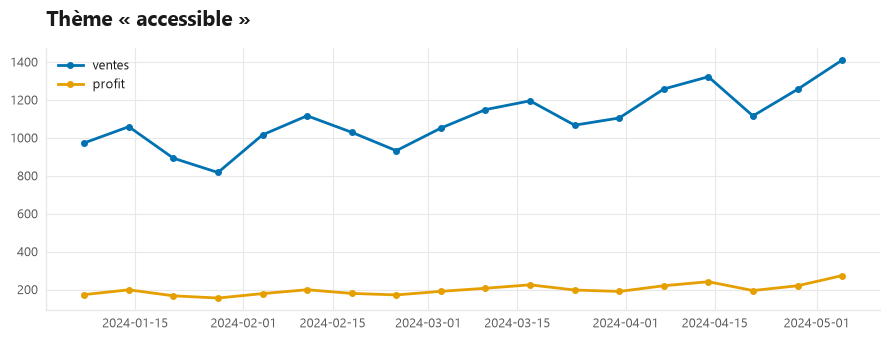

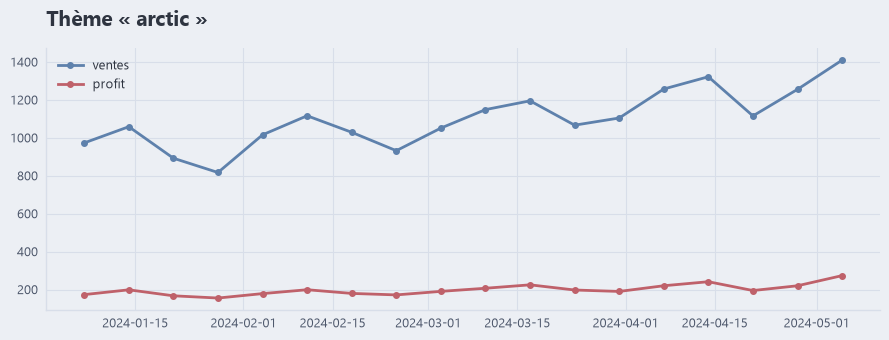

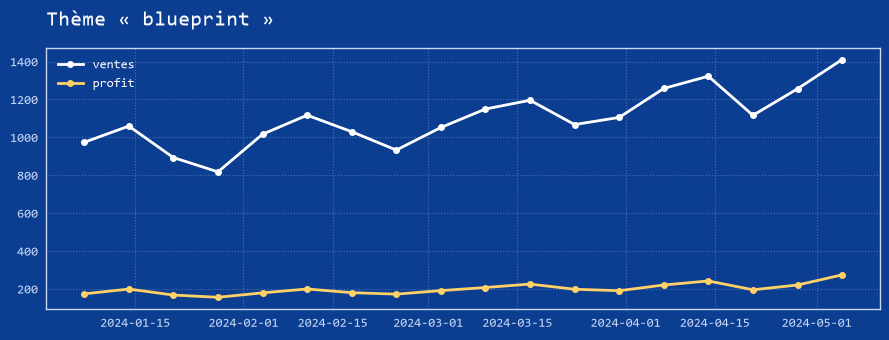

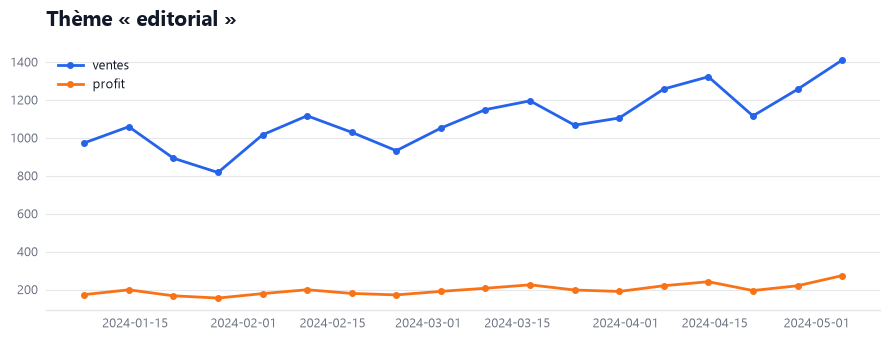

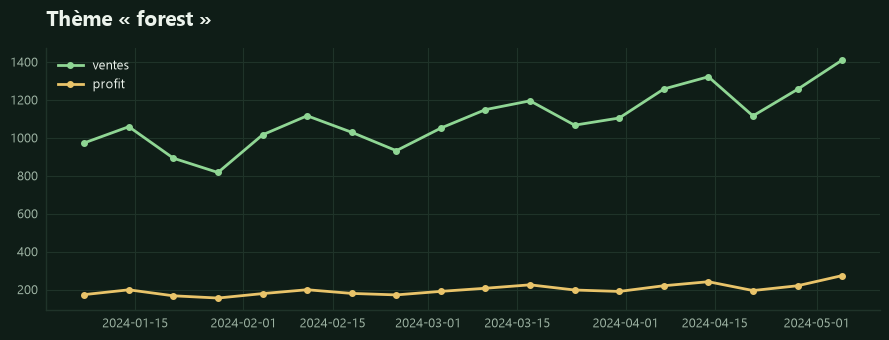

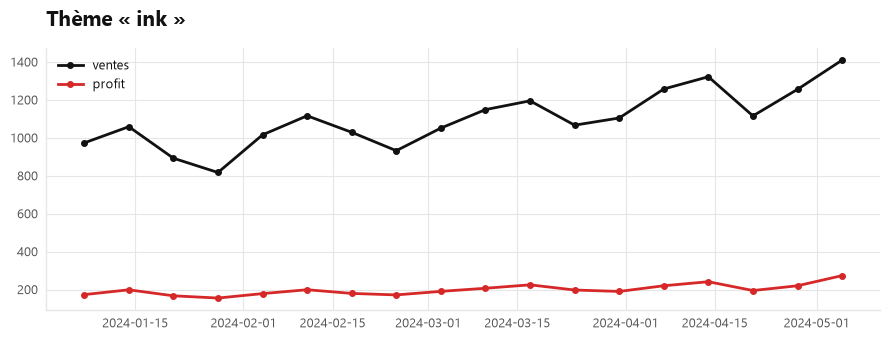

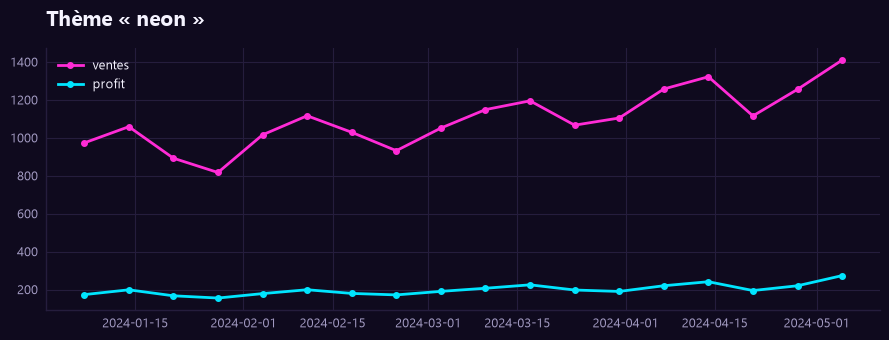

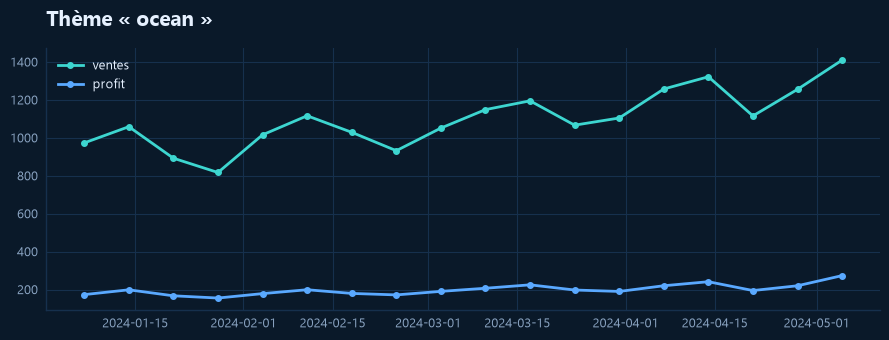

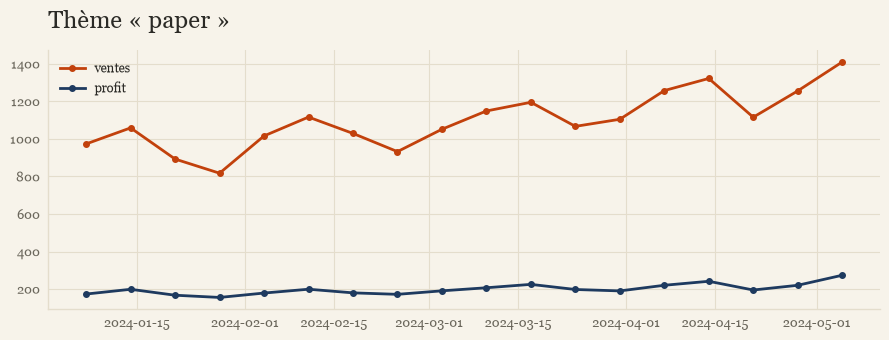

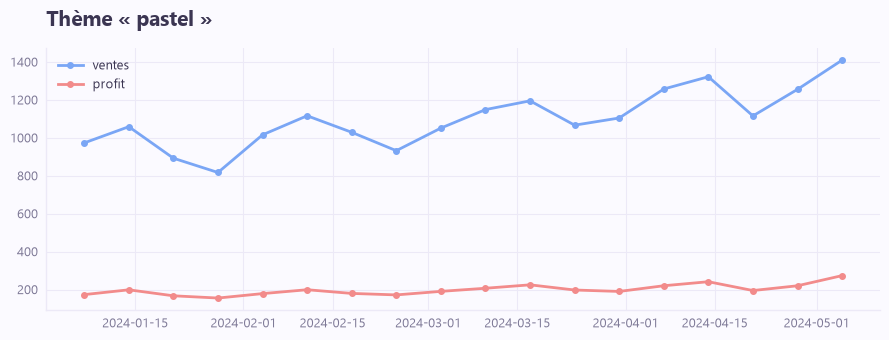

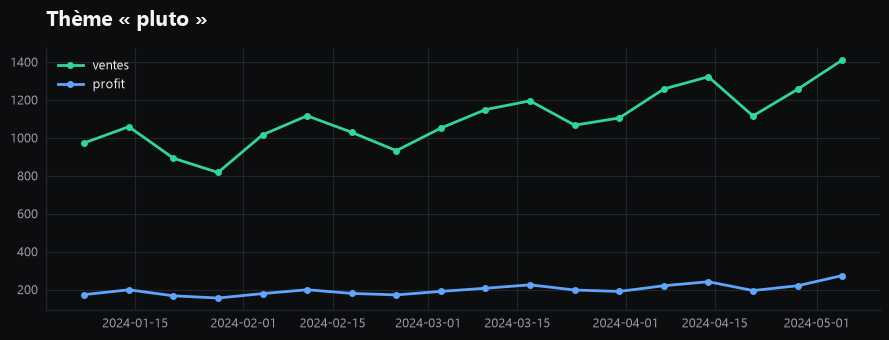

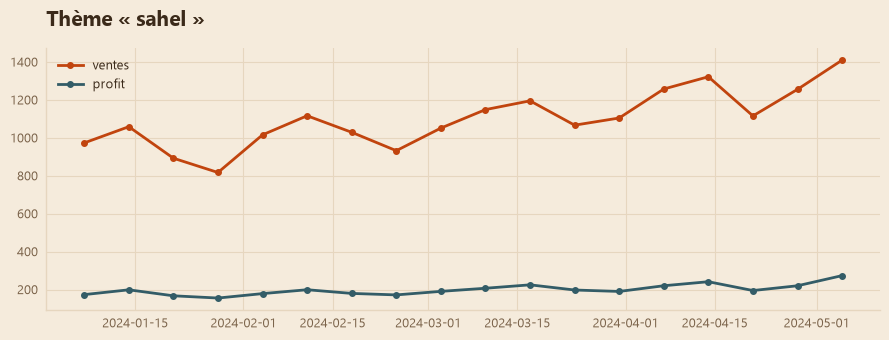

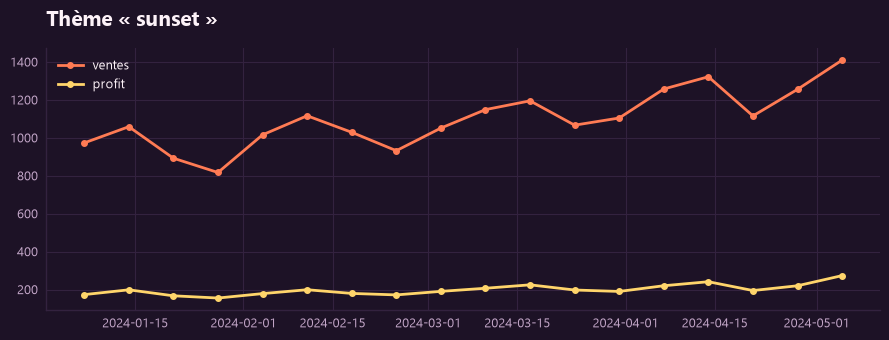

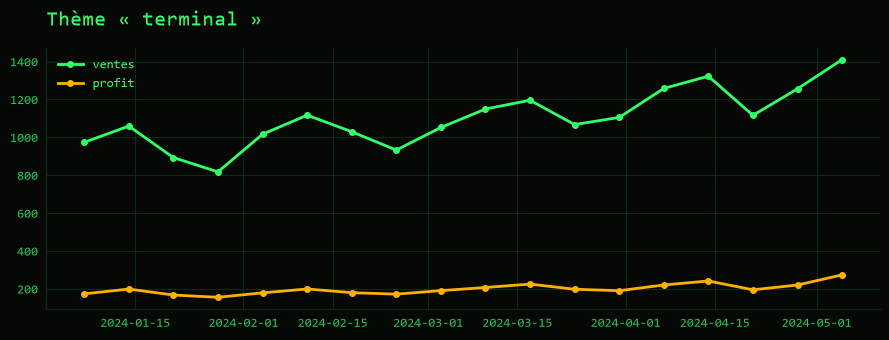

In [8]:
for nom in list_themes():
    with theme_context(nom):
        (Chart(hebdo, figsize=(9, 3.5))
            .line('date', ['ventes', 'profit'], marker='o', markersize=4)
            .title(f'Thème « {nom} »')
            .set_legend()
            .tight_layout()
            .show())

`set_theme` applique un thème à toute la session (comme `seaborn.set_theme`) ; `set_theme(None)` revient au style matplotlib.

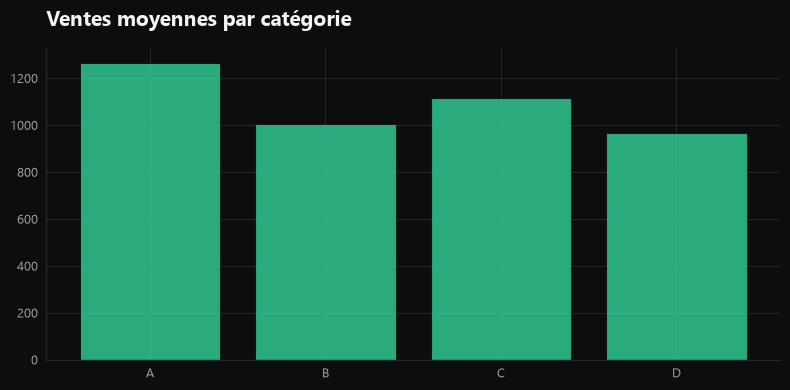

In [9]:
set_theme('pluto')
(Chart(par_categorie, figsize=(8, 4))
    .bar('categorie', 'ventes')
    .title('Ventes moyennes par catégorie')
    .tight_layout()
    .show())
set_theme(None)

## 6. Palettes de couleurs

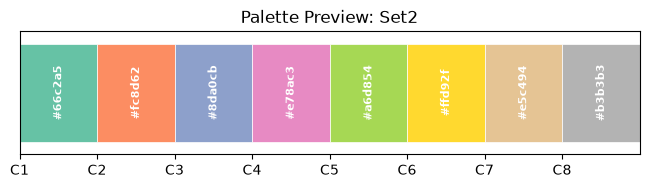

In [10]:
Chart(ventes, figsize=(8, 1.6)).preview_palette('Set2').show()

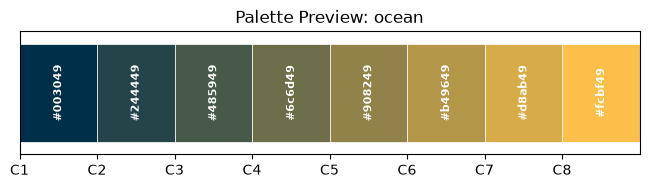

In [11]:
(Chart(ventes, figsize=(8, 1.6))
    .generate_gradient_palette('ocean', '#003049', '#fcbf49', n_colors=8)
    .preview_palette('ocean')
    .show())

## 7. Polices

`font()` modifie la police globale de matplotlib : on l'isole dans `plt.rc_context()` pour ne pas affecter les graphiques suivants.

In [12]:
get_fonts(pattern='Times')

['Times New Roman']

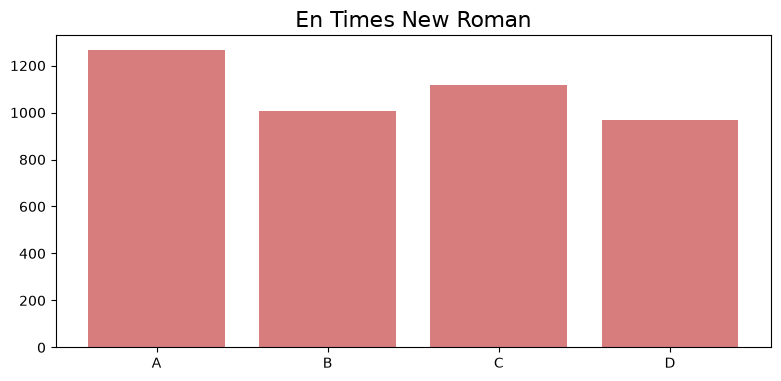

In [13]:
with plt.rc_context():
    (Chart(par_categorie, figsize=(8, 4))
        .font('Times New Roman', size=13)
        .bar('categorie', 'ventes', color='indianred')
        .title('En Times New Roman')
        .tight_layout()
        .show())

## 8. Export

Appeler `save()` **avant** `show()` : `show()` ferme la figure pour libérer la mémoire.

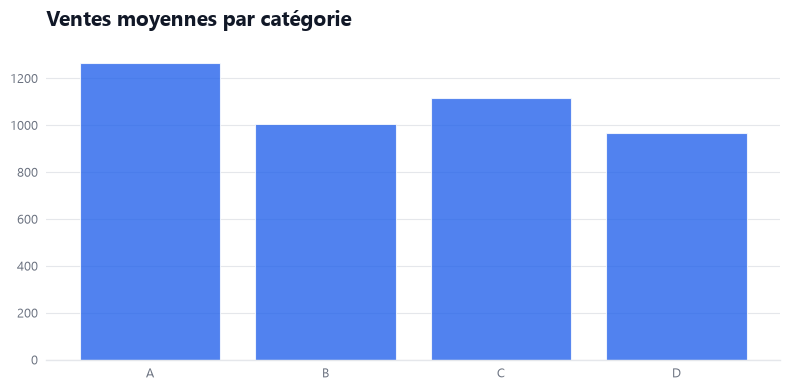

Enregistré : C:\Users\ORDINA~1\AppData\Local\Temp\ventes_par_categorie.png (19 Ko)


In [14]:
fichier = Path(tempfile.gettempdir()) / 'ventes_par_categorie.png'

(Chart(par_categorie, figsize=(8, 4), theme='editorial')
    .bar('categorie', 'ventes')
    .title('Ventes moyennes par catégorie')
    .tight_layout()
    .save(fichier, dpi=150)
    .show())
set_theme(None)
print(f'Enregistré : {fichier} ({fichier.stat().st_size // 1024} Ko)')